# Pitch Uniqueness with k-Nearest Neighbors (2024–2026)

**Question:** Which MLB pitches are the most unique compared with pitches thrown by other pitchers, judged on four measurements: velocity, horizontal break, vertical break and arm angle?

This notebook produces three charts:
1. **Most unique pitches overall:** k-nearest neighbors (k = 5) on all pitches.
2. **Arm angles of every pitcher-season:** a simple histogram that explains why one pitcher dominates chart 1.
3. **Most unusual pitch within each pitch type:** the same k-nearest-neighbor method, but each pitch is only compared with pitches of its own type.

**A boiled down explanation of the methods:** a pitch is unique if even its 5 most similar pitches (its "nearest neighbors") thrown by other pitchers are still far away from it.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
DERIVED = Path("derived")

%config InlineBackend.figure_format = 'retina'

# Chart styling
GRAY, INK, SUBTLE = '#c3c2b7', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': SUBTLE, 'axes.titlecolor': INK,
    'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

# One color per pitch type (checked so neighboring pitch types stay distinguishable for colorblind readers)
PITCH_ORDER = ['FF', 'SI', 'FC', 'SL', 'ST', 'CU', 'CH', 'FS']
PITCH_COLORS = {'FF': '#008300', 'SI': '#1baf7a', 'FC': '#e87ba4', 'SL': '#eda100', 'ST': '#e34948',
                'CU': '#2a78d6', 'CH': '#6250d6', 'FS': '#eb6834', 'Other': '#898781'}
PITCH_NAMES = {'FF': 'Four-seam', 'SI': 'Sinker', 'FC': 'Cutter', 'SL': 'Slider', 'ST': 'Sweeper',
               'CU': 'Curveball', 'CH': 'Changeup', 'FS': 'Splitter', 'SV': 'Slurve', 'FO': 'Forkball',
               'KN': 'Knuckleball', 'Other': 'Other (SV, FO, KN)'}


def pitch_legend(ax, types, **kwargs):
    '''Legend with one colored dot per pitch type.'''
    handles = [plt.Line2D([], [], marker='o', ls='', markersize=7, color=PITCH_COLORS[t],
                          label=PITCH_NAMES[t] if t == 'Other' else f'{t} {PITCH_NAMES[t]}')
               for t in types]
    return ax.legend(handles=handles, frameon=False, **kwargs)

In [2]:
data = pd.read_csv(DERIVED / 'data24-26.csv')
print(data.shape)
data[['name', 'year', 'hand', 'pitch_type', 'n_pitches', 'avg_speed',
      'pitcher_break_x', 'pitcher_break_z_induced', 'ball_angle']].head()

(3677, 53)


,name,year,hand,pitch_type,n_pitches,avg_speed,pitcher_break_x,pitcher_break_z_induced,ball_angle
0,"Webb, Logan",2024,R,SI,1270,92.6,15.1,1.1,22.1
1,"Webb, Logan",2024,R,CH,990,87.4,9.8,-4.8,22.1
2,"Webb, Logan",2024,R,ST,680,83.8,16.4,-0.9,22.1
3,"Webb, Logan",2024,R,FF,176,92.6,8.6,9.2,22.1
4,"Nola, Aaron",2024,R,CU,1049,79.1,14.0,-9.9,20.1


---
## Step 1: Preparing the data

**What one row is:** one pitcher's pitch type in one season (for example, Tyler Rogers' 2024 slider). There are 3,677 of these, and they are what we compare.

**The four measurements:**

| column | what it measures |
|---|---|
| `avg_speed` | average velocity (mph) |
| `arm_break` | horizontal break (inches): **+ toward the pitcher's arm side, − toward his glove side** |
| `pitcher_break_z_induced` | induced vertical break (inches): how much the pitch "rises" or drops from spin, with gravity removed |
| `ball_angle` | arm angle (degrees): 90 = straight over the top, 0 = sidearm, negative = submarine |

**One fix first.** The raw horizontal break column, `pitcher_break_x`, is never negative. A sinker breaking 15 inches one way and a sweeper breaking 14 inches the *other* way would look almost identical. We use the league-average direction (`league_break_x`, `diff_x`) to give each pitch's break a sign. Because we measure arm side vs. glove side, a lefty's slider and a righty's slider count as mirror images of the same pitch.

In [3]:
# Give horizontal break a direction: + = arm side, - = glove side (same logic as Visualizations.ipynb)
league_dir = np.where(data['league_break_x'] < 0, 1, -1)              # which way the league average breaks
league_dir = np.where(data['league_break_x'].isna(), 1, league_dir)   # forkballs have no league average: arm side
toward_league = data['league_break_x'].abs() + data['diff_x']         # < 0 means this pitch broke the OPPOSITE way
same_dir = np.where(toward_league.isna() | (toward_league >= 0), 1, -1)
data['arm_break'] = data['pitcher_break_x'] * league_dir * same_dir

FEATURES = ['avg_speed', 'arm_break', 'pitcher_break_z_induced', 'ball_angle']
data['label'] = data['name'] + ' ' + data['year'].astype(str) + ' ' + data['pitch_type']
# SV, FO and KN have only 28 rows combined, so they share one gray "Other" color in the charts
data['type_group'] = np.where(data['pitch_type'].isin(PITCH_ORDER), data['pitch_type'], 'Other')

# Check: fastballs, sinkers, changeups should be + (arm side); sliders, sweepers, curveballs - (glove side)
data.groupby('pitch_type')['arm_break'].mean().round(1)

pitch_type
CH    14.1
CU    -8.7
FC    -1.9
FF     7.9
FO     8.1
FS    10.8
KN     7.1
SI    14.9
SL    -4.2
ST   -13.6
SV   -11.8
Name: arm_break, dtype: float64

---
## Step 2: How k-nearest neighbors measures uniqueness

1. **Put every measurement on the same scale (z-scores).** Each value becomes "how many standard deviations above or below average": $z = \frac{x - \text{mean}}{\text{SD}}$. Without this, velocity (70–101 mph) would swamp break (about −20 to +20 inches). After this step, every measurement gets an equal vote.
2. **Measure the distance between pitches.** Use ordinary straight-line (Euclidean) distance between two points in that 4-D space. A distance of 0 means identical pitches; the units are standard deviations.
3. **Find each pitch's k = 5 nearest neighbors** using scikit-learn's `NearestNeighbors`. **Only pitches thrown by a different pitcher count.** Otherwise Rogers' 2024 slider would just match his own 2026 slider. Because k-NN would also return the pitcher's own pitches, we ask it for extra neighbors, drop the ones from the same pitcher, and keep the closest 5.
4. **Uniqueness score = the average distance to those 5 neighbors.** A bigger score means a more one-of-a-kind pitch. We average 5 neighbors instead of using just 1 so that a single lookalike can't make an unusual pitch look ordinary.

The function below does all four steps. It is used for chart 1 (all pitches together) and for chart 3 (one pitch type at a time).

In [4]:
def knn_uniqueness(df, features=FEATURES, k=5):
    '''Average distance from each pitch to its k nearest neighbors thrown by OTHER pitchers.
    Returns (scores, neighbor labels), lined up with df's rows.'''
    df = df.reset_index(drop=True)
    Z = (df[features] - df[features].mean()) / df[features].std()        # step 1: z-scores

    # steps 2-3: ask for extra neighbors so we still have k left after dropping the pitcher's own pitches
    extra = df.groupby('id').size().max()
    knn = NearestNeighbors(n_neighbors=min(k + extra, len(df)), metric='euclidean').fit(Z)
    dist, idx = knn.kneighbors(Z)                                         # each row: nearest pitches, closest first

    ids, labels = df['id'].to_numpy(), df['label'].to_numpy()
    scores, neighbors = [], []
    for i in range(len(df)):
        other = ids[idx[i]] != ids[i]                                     # keep only other pitchers' pitches
        scores.append(dist[i][other][:k].mean())                          # step 4: average distance to k nearest
        neighbors.append(' | '.join(labels[idx[i][other][:k]]))
    return np.array(scores), neighbors

---
## Chart 1: Most unique pitches overall

Run k-NN (k = 5) on all 3,677 pitches together, using all four measurements, then rank pitches by their uniqueness score. Each pitcher-pitch type is shown once (its most unique season), so one pitch doesn't fill the list with three seasons.

In [5]:
data['uniqueness'], data['nearest_5'] = knn_uniqueness(data)

show = ['label', 'pitch_type_qualified', 'n_pitches'] + FEATURES + ['uniqueness']
unique_all = data.sort_values('uniqueness', ascending=False).drop_duplicates(['id', 'pitch_type'])
unique_all[show].head(12).round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,uniqueness
1139,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,5.26
1138,"Rogers, Tyler 2024 SI",True,640,82.4,1.0,-10.7,-64.1,4.78
1167,"Hill, Tim 2024 SL",False,51,82.2,1.3,5.2,-19.6,2.05
1165,"Hill, Tim 2024 SI",True,675,88.7,15.6,-5.3,-19.6,1.57
2068,"Milner, Hoby 2025 CH",False,201,81.1,16.0,-4.1,-6.0,1.52
1166,"Hill, Tim 2024 FF",False,256,90.7,17.6,4.1,-19.6,1.45
170,"Flexen, Chris 2024 CU",True,342,72.0,-7.2,-15.7,70.1,1.32
171,"Flexen, Chris 2024 ST",False,209,80.0,-11.9,-3.1,70.1,1.26
2069,"Milner, Hoby 2025 FF",False,164,87.9,15.2,6.6,-6.0,1.20
625,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,1.06


In [6]:
# Who are the 5 nearest neighbors of the most unique pitch?
top = unique_all.iloc[0]
print(f"5 nearest neighbors of {top['label']} (average distance {top['uniqueness']:.2f} SD):")
for n in top['nearest_5'].split(' | '):
    print('  ', n)

5 nearest neighbors of Rogers, Tyler 2024 SL (average distance 5.26 SD):
   Hill, Tim 2024 SL
   Thompson, Ryan 2024 SL
   Milner, Hoby 2025 ST
   Hill, Tim 2024 FF
   Milner, Hoby 2024 ST


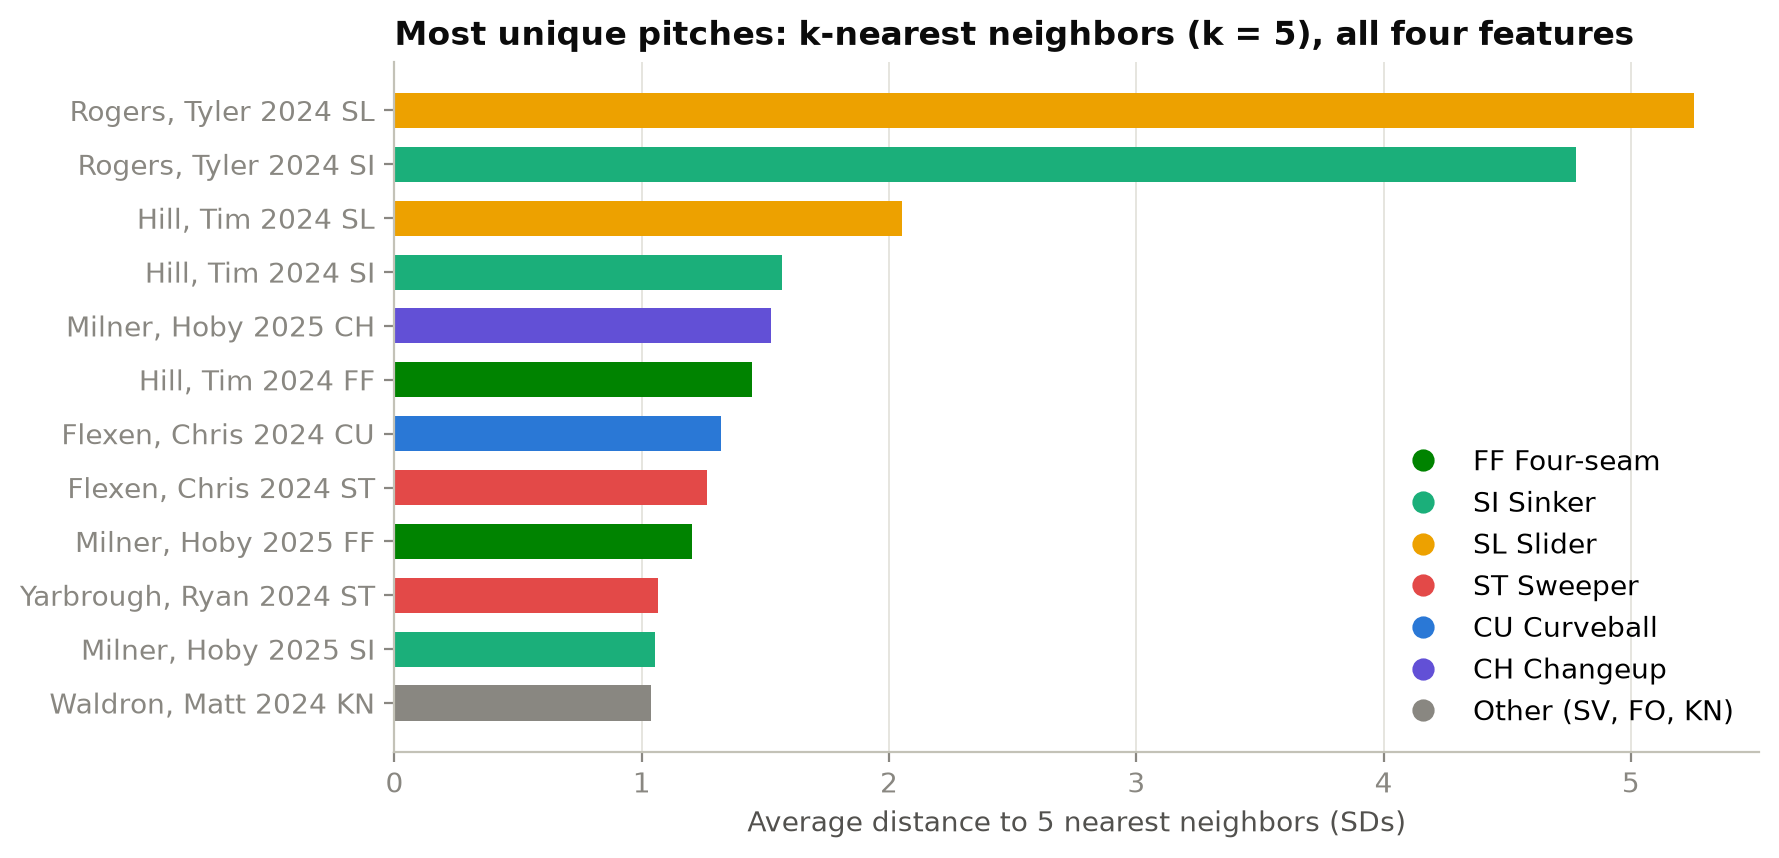

In [7]:
top_u = unique_all.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(top_u['label'], top_u['uniqueness'], color=top_u['type_group'].map(PITCH_COLORS), height=0.65)
ax.set_xlabel('Average distance to 5 nearest neighbors (SDs)')
ax.set_title('Most unique pitches: k-nearest neighbors (k = 5), all four features', loc='left')
ax.grid(axis='y', visible=False)
pitch_legend(ax, [t for t in PITCH_ORDER + ['Other'] if t in set(top_u['type_group'])], loc='lower right')
plt.tight_layout()
plt.show()

**What this shows:** Tyler Rogers' 2024 slider is the most unique pitch in the data, and his sinker is second. Both sit about 5 standard deviations from their nearest neighbors, more than twice the score of anything else. Even his 5 nearest neighbors all come from other low-arm-slot pitchers (Tim Hill, Ryan Thompson, Hoby Milner), yet they are still far away. Look at the `ball_angle` column: the top of the list is dominated by pitchers with very low arm angles. Chart 2 shows why.

---
## Chart 2: Arm angles of every pitcher-season

**Method:** no k-NN here. This is a plain histogram of the `ball_angle` column. Every pitch a pitcher throws in a season has the same arm angle, so we first keep **one row per pitcher-season** (otherwise pitchers with more pitch types would be counted several times). The three lowest arm angles are labeled.

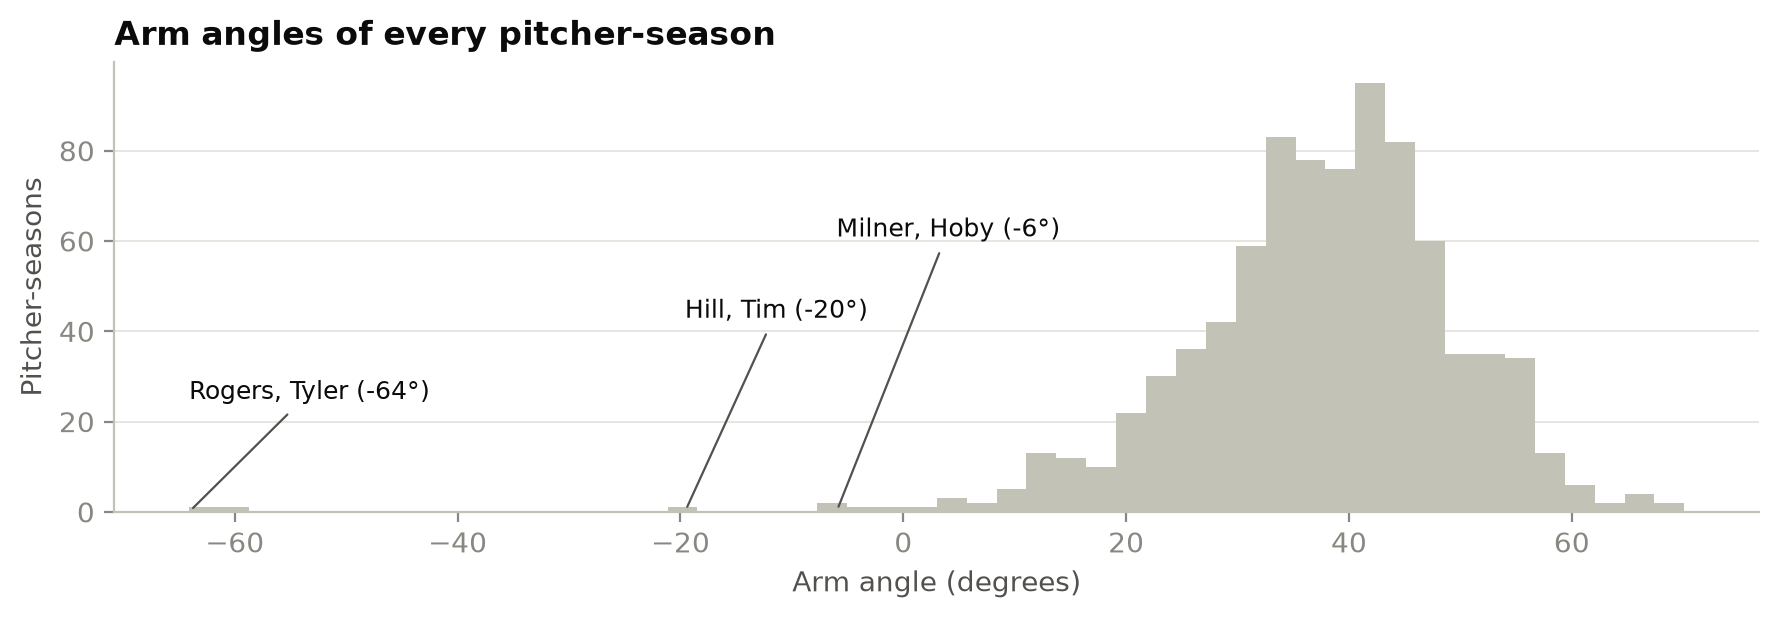

In [8]:
slots = data.drop_duplicates(['id', 'year'])                              # one row per pitcher-season
lowest = slots.sort_values('ball_angle').drop_duplicates('id').head(3)    # the 3 lowest arm angles

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(slots['ball_angle'], bins=50, color=GRAY)
for i, (_, row) in enumerate(lowest.iterrows()):
    ax.annotate(f"{row['name']} ({row['ball_angle']:.0f}°)", xy=(row['ball_angle'], 0),
                xytext=(row['ball_angle'], 25 + 18 * i), color=INK, fontsize=9,
                arrowprops=dict(arrowstyle='-', color=SUBTLE, lw=0.8))
ax.set_xlabel('Arm angle (degrees)')
ax.set_ylabel('Pitcher-seasons')
ax.set_title('Arm angles of every pitcher-season', loc='left')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**What this shows:** most pitchers throw from an arm angle between about 20° and 60°. Tyler Rogers throws from **−64°**, a submarine delivery more than 40° lower than anyone else. Arm angle is one of the four measurements in the k-NN distance, so this gap alone pushes every pitch he throws to the top of chart 1. Tim Hill (−20°) and Hoby Milner (−6°) are the next lowest, and they also fill the top of chart 1.

---
## Chart 3: Most unusual pitch within each pitch type

A slider competes with other sliders, not with fastballs. So here we ask: **who throws the most unusual slider, the most unusual curveball, and so on?**

**Method:** the same k-NN uniqueness score (k = 5) from Step 2, with two changes:
1. **Each pitch type is analyzed separately.** Sliders are compared only with sliders, sinkers only with sinkers, and so on.
2. **The z-scores are recalculated within each pitch type**, using that type's own average and spread. A slider is judged against what is normal *for a slider*, not for all pitches.

Pitch types with fewer than 20 rows (knuckleball and forkball) are skipped, since there are too few to define "normal."

In [9]:
results = []
for pitch_type, group in data.groupby('pitch_type'):
    if len(group) < 20:
        continue
    group = group.reset_index(drop=True)
    group['uniqueness_within'], group['nearest_5_within'] = knn_uniqueness(group)
    results.append(group)
within = pd.concat(results)

most_unique_by_type = (within.sort_values('uniqueness_within', ascending=False)
                             .drop_duplicates('pitch_type')
                             .set_index('pitch_type')
                             .loc[[t for t in PITCH_ORDER + ['SV'] if t in set(within['pitch_type'])]])
most_unique_by_type[show[:-1] + ['uniqueness_within']].round(2)

,label,pitch_type_qualified,n_pitches,avg_speed,arm_break,pitcher_break_z_induced,ball_angle,uniqueness_within
pitch_type,,,,,,,,
FF,"Hill, Tim 2024 FF",False,256,90.7,17.6,4.1,-19.6,2.72
SI,"Rogers, Tyler 2024 SI",True,640,82.4,1.0,-10.7,-64.1,8.99
FC,"Strickland, Hunter 2024 FC",True,363,84.0,-13.0,4.5,31.7,3.34
SL,"Rogers, Tyler 2024 SL",True,356,73.6,-8.9,15.4,-64.1,6.91
ST,"Yarbrough, Ryan 2024 ST",True,411,71.3,-15.0,6.1,13.5,2.34
CU,"Flexen, Chris 2024 CU",True,342,72.0,-7.2,-15.7,70.1,1.82
CH,"Milner, Hoby 2025 CH",False,201,81.1,16.0,-4.1,-6.0,2.24
FS,"Griffin, Foster 2026 FS",False,160,81.3,0.7,0.6,44.7,1.76
SV,"Vodnik, Victor 2026 SV",False,70,87.3,-5.3,-9.4,43.7,2.83


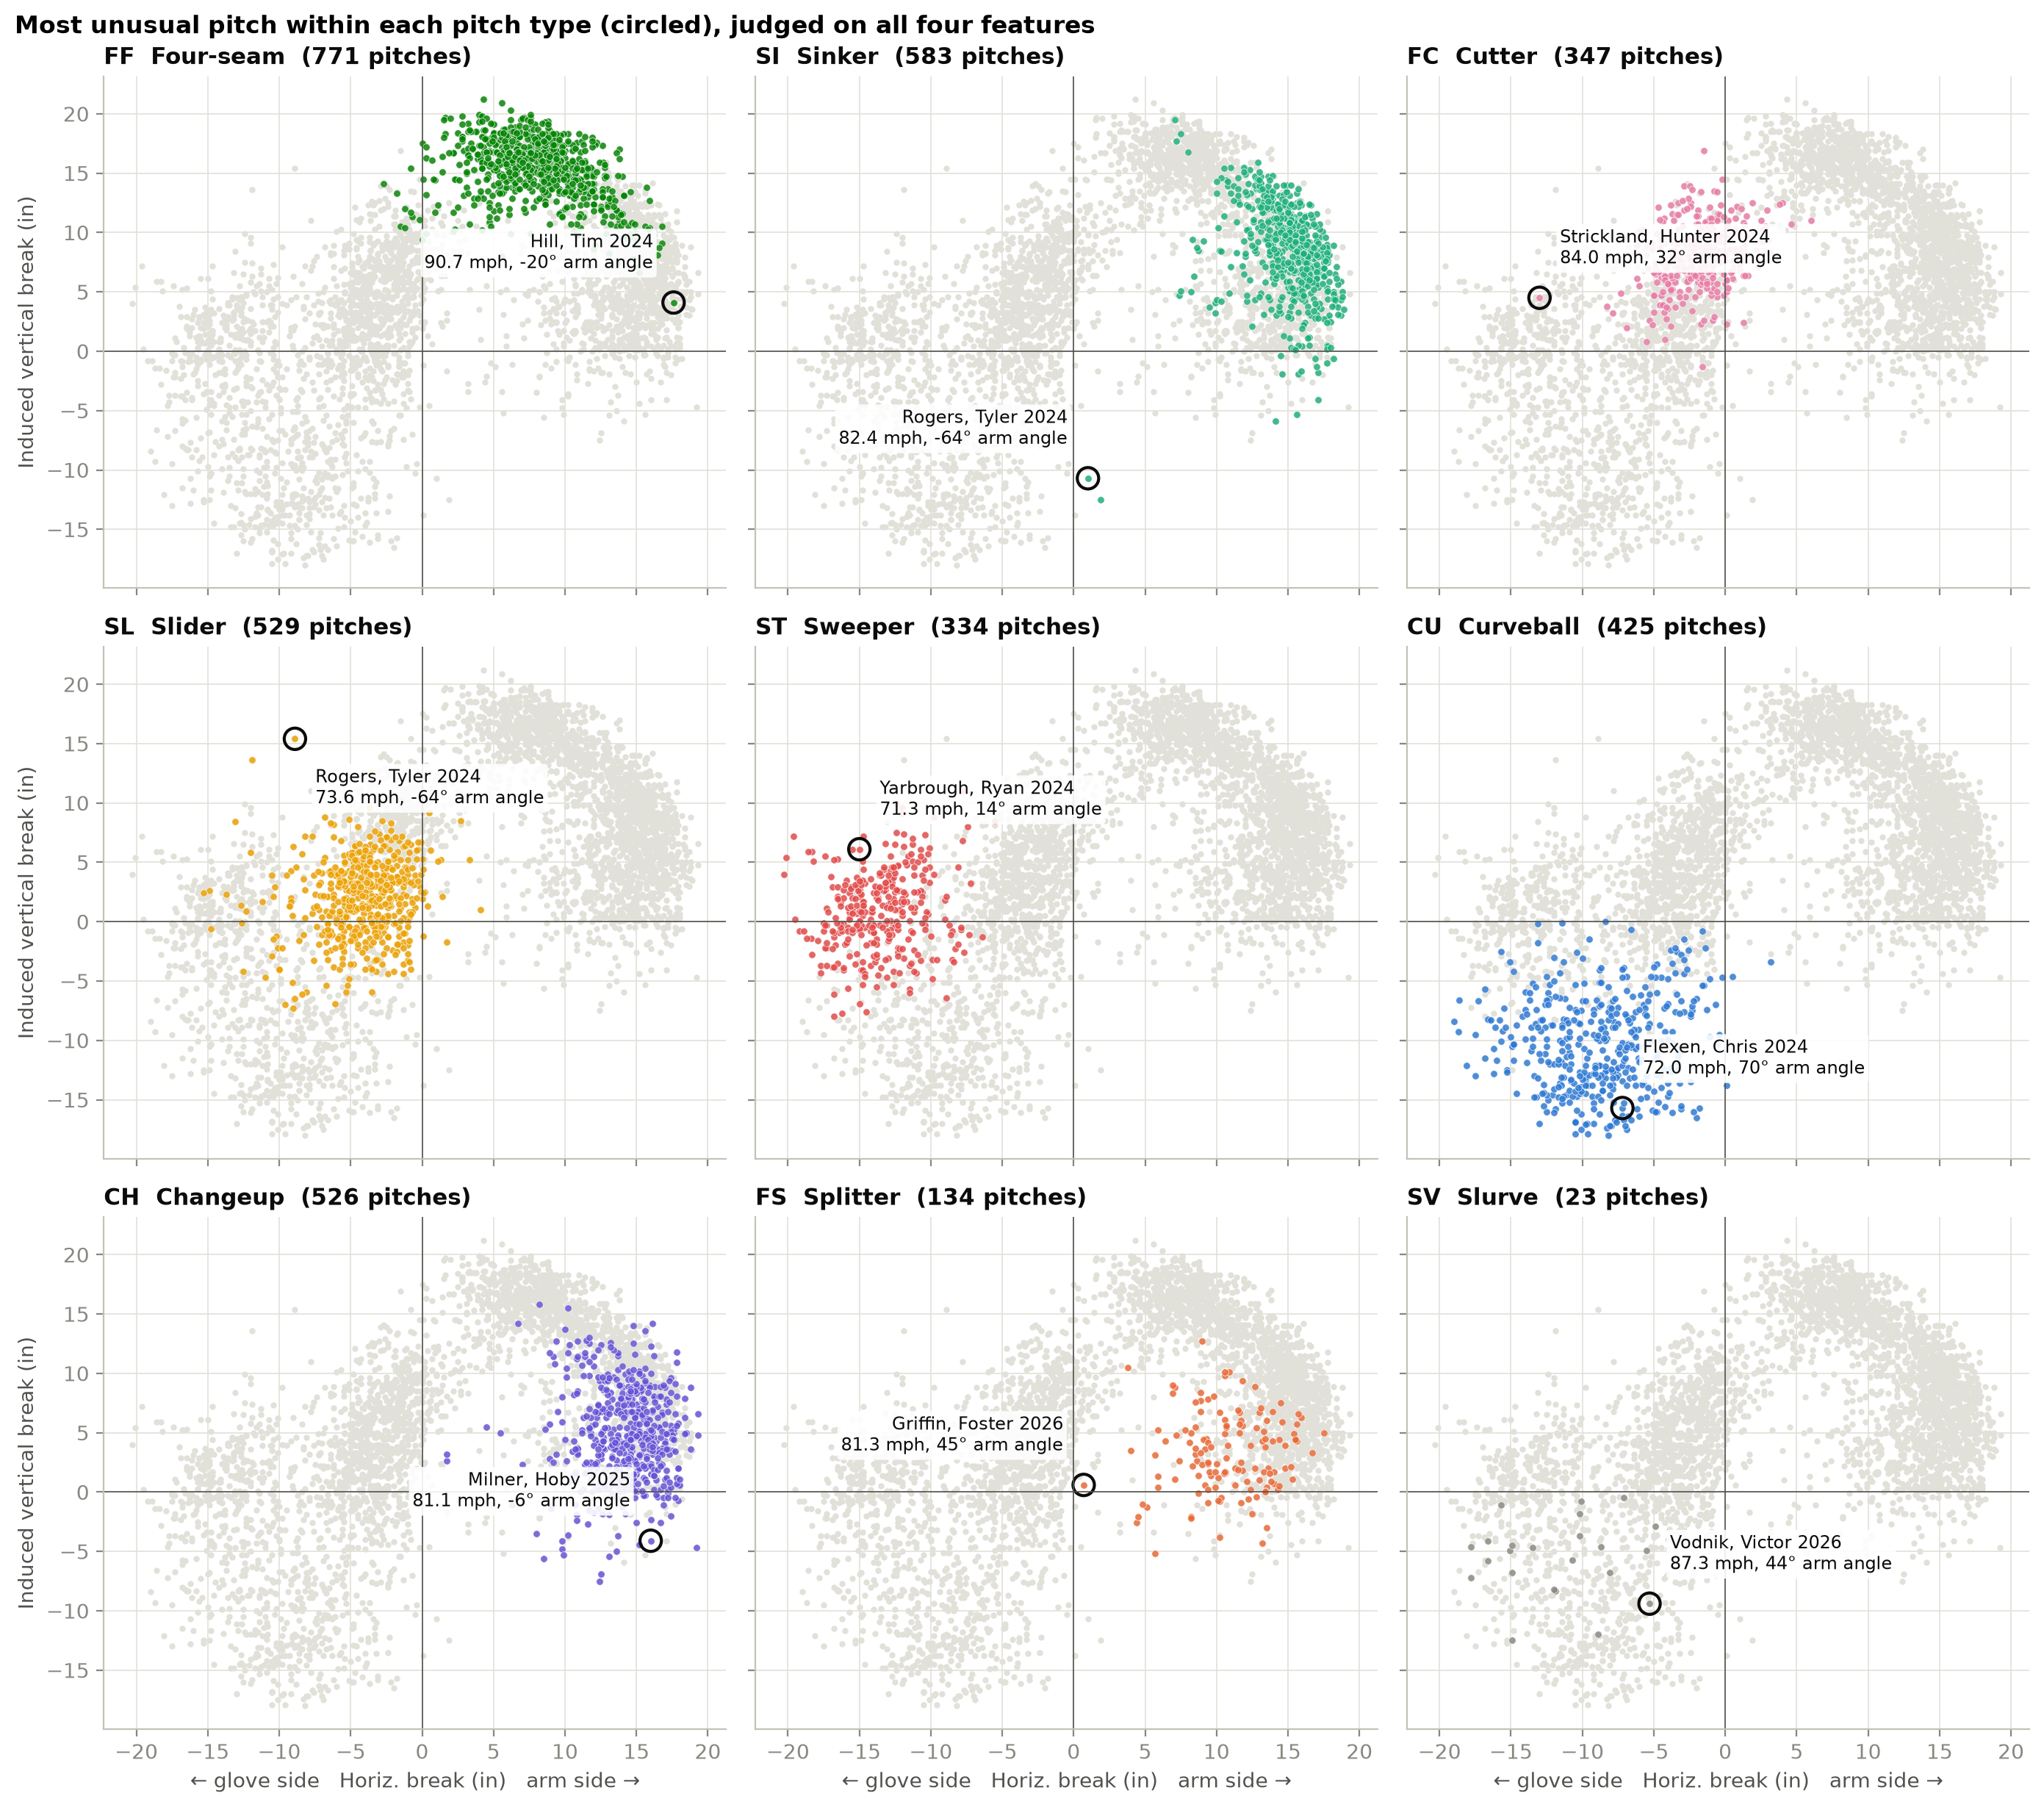

In [10]:
# One small chart per pitch type: that type in its color, every other pitch in light gray for context,
# and the most unusual pitch of that type circled
type_list = list(most_unique_by_type.index)

fig, axes = plt.subplots(3, 3, figsize=(14, 12.5), sharex=True, sharey=True)
for ax, t in zip(axes.flat, type_list):
    ax.scatter(data['arm_break'], data['pitcher_break_z_induced'], s=4, color='#e1e0d9')
    group = within[within['pitch_type'] == t]
    color = PITCH_COLORS.get(t, PITCH_COLORS['Other'])
    ax.scatter(group['arm_break'], group['pitcher_break_z_induced'], s=12, color=color, alpha=0.8,
               edgecolor='white', linewidth=0.3)

    star = most_unique_by_type.loc[t]
    ax.scatter(star['arm_break'], star['pitcher_break_z_induced'], s=110, facecolor='none', edgecolor=INK, linewidth=1.5)
    to_left = star['arm_break'] > 0                    # write the label toward the middle of the chart
    to_below = star['pitcher_break_z_induced'] > 10
    ax.annotate(f"{star['name']} {star['year']}\n{star['avg_speed']:.1f} mph, {star['ball_angle']:.0f}° arm angle",
                (star['arm_break'], star['pitcher_break_z_induced']),
                xytext=(-10 if to_left else 10, -14 if to_below else 14), textcoords='offset points',
                ha='right' if to_left else 'left', va='top' if to_below else 'bottom', fontsize=8.5, color=INK,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9))
    ax.axhline(0, color=SUBTLE, lw=0.6)
    ax.axvline(0, color=SUBTLE, lw=0.6)
    ax.set_title(f"{t}  {PITCH_NAMES[t]}  ({len(group)} pitches)", loc='left', fontsize=11)

for ax in axes[-1]:
    ax.set_xlabel('← glove side   Horiz. break (in)   arm side →')
for ax in axes[:, 0]:
    ax.set_ylabel('Induced vertical break (in)')
fig.suptitle('Most unusual pitch within each pitch type (circled), judged on all four features',
             fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**How to read it:** each small chart is a movement plot (horizontal break vs. vertical break). The colored dots are one pitch type, the gray dots are every other pitch for context, and the circled dot is that type's most unusual pitch.

**What this shows:**
* **Some winners are movement outliers.** Rogers' sinker drops far more than any other sinker, his slider *rises* 15 inches, and Hunter Strickland's cutter breaks 13 inches to the glove side, which is more like a slider.
* **Some winners sit inside their cluster.** Chris Flexen's curveball moves like a normal curveball. It is unusual because of its 70° arm angle, the highest in the data. The movement chart can't show velocity or arm angle, so each label lists both.
* **Arm angle still matters within types.** Rogers (−64°), Tim Hill (−20°) and Hoby Milner (−6°) have the most unusual sinker, slider, four-seamer and changeup.
* **Watch small samples.** Victor Vodnik's slurve (70 pitches) and Foster Griffin's splitter (160 pitches) come from fewer pitches thrown.

---
## Summary of methods

| Chart | Method | Compared against | Result |
|---|---|---|---|
| 1. Most unique pitches | k-nearest neighbors, k = 5: average distance to the 5 most similar pitches by other pitchers, on z-scored velocity, horizontal break, vertical break and arm angle | All 3,677 pitch-seasons | Tyler Rogers' 2024 slider (5.26 SD) |
| 2. Arm angles | Histogram of arm angle, one row per pitcher-season | All pitcher-seasons | Rogers at −64°, 44° below the next pitcher |
| 3. Most unusual within each type | Same k-NN (k = 5), run separately for each pitch type with z-scores recalculated within that type | Only pitches of the same type | Rogers (SI, SL), Hill (FF), Milner (CH), Strickland (FC), Yarbrough (ST), Flexen (CU), Griffin (FS), Vodnik (SV) |